# UN Comtrade Data Exploration

**Goal:** Explore the real annual import data for Cameroon from UN Comtrade.
We want to understand import volumes over time, the value vs. quantity relationship, and which commodities dominate the trade profile.

**Note:** The dataset was restricted during ETL to the 4 commodities that have both WFP prices and Comtrade data: `rice`, `maize`, `wheat_flour`, and `oil`.

In [1]:
import sys
from pathlib import Path

# Set project root to allow importing src
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.config.settings import settings

# Plotting style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")
pd.set_option('display.max_columns', None)

print("Libraries loaded.")

Libraries loaded.


## 1. Load and Merge Data

We load the trade fact table and join the product dimension to get readable names. We also extract the year from `date_id`.

In [2]:
# Load datasets
fact_trade = pd.read_parquet(settings.data_processed_dir / "fact_trade.parquet")
dim_product = pd.read_parquet(settings.data_processed_dir / "dim_product.parquet")

# Merge and clean
df = fact_trade.merge(dim_product[["product_id", "product_name"]], on="product_id", how="left")
df["year"] = df["date_id"] // 10000

# Aggregate by year and product (in case there are multiple partner records)
# For this exploration, we look at total imports from all partners.
df_agg = df.groupby(["year", "product_name"]).agg(
    import_quantity=("import_quantity", "sum"),
    import_value=("import_value", "sum")
).reset_index()

print(f"Total trade records: {len(df):,}")
print(f"Aggregated yearly records: {len(df_agg):,}")
display(df_agg.head())

Total trade records: 76
Aggregated yearly records: 76


,year,product_name,import_quantity,import_value
0,2005,maize,12782016.0,2928142.0
1,2005,oil,0.0,15533838.0
2,2005,rice,433032593.0,136924154.0
3,2005,wheat_flour,300148056.0,72568894.0
4,2006,maize,4041721.0,1209182.0


## 2. Import Volumes Over Time

How has the physical volume of imports changed over the years? This is the variable we use as a supply ceiling in the synthetic engine.

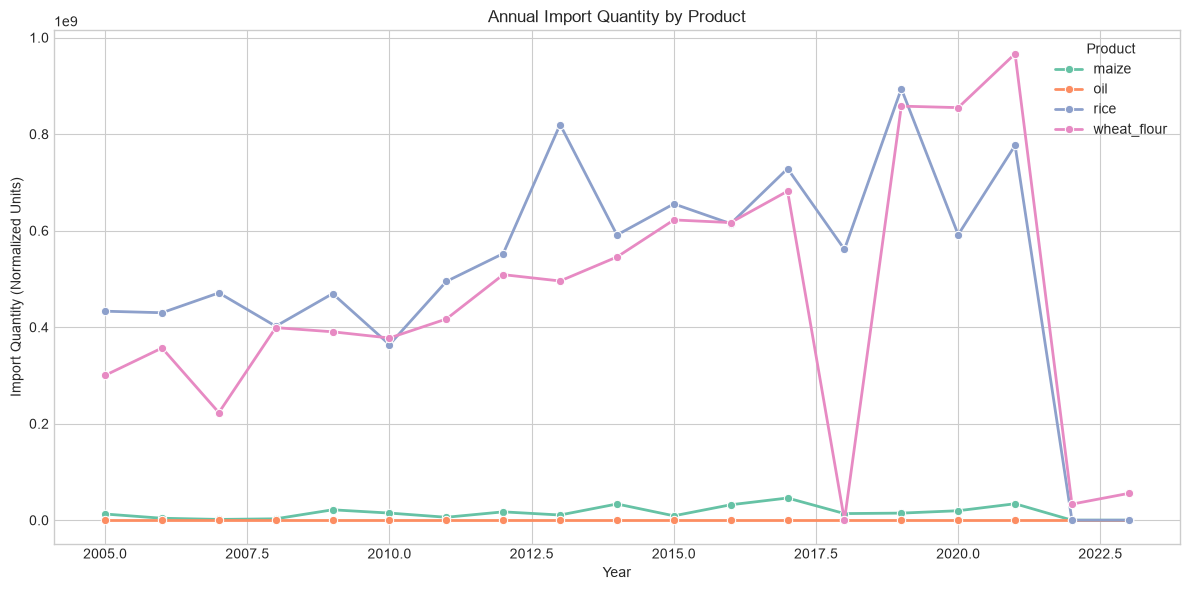

In [3]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_agg, x='year', y='import_quantity', hue='product_name', marker='o', linewidth=2)
plt.title("Annual Import Quantity by Product")
plt.xlabel("Year")
plt.ylabel("Import Quantity (Normalized Units)")
plt.legend(title="Product")
plt.tight_layout()
plt.show()

## 3. Import Value Over Time

How much money (USD) is spent on these imports? Compare this to the physical volume to see if price inflation (or deflation) is driving the value.

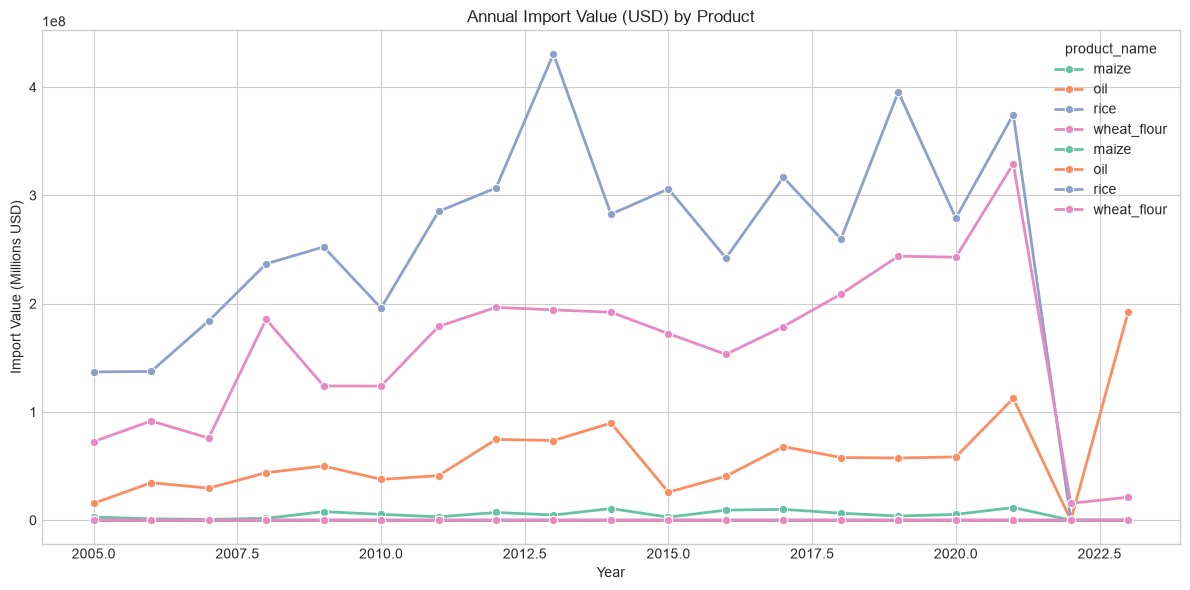

In [4]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_agg, x='year', y='import_value', hue='product_name', marker='o', linewidth=2)
plt.title("Annual Import Value (USD) by Product")
plt.xlabel("Year")
plt.ylabel("Import Value (Millions USD)")
# Scale to millions for readability
df_agg['import_value_millions'] = df_agg['import_value'] / 1_000_000
sns.lineplot(data=df_agg, x='year', y='import_value_millions', hue='product_name', marker='o', linewidth=2)
plt.ylabel("Import Value (Millions USD)")
plt.tight_layout()
plt.show()

## 4. Unit Value (Implied Import Price)

We can calculate the implied unit value (Value / Quantity) to see how the cost of imports per unit has evolved. This is a proxy for international commodity prices.

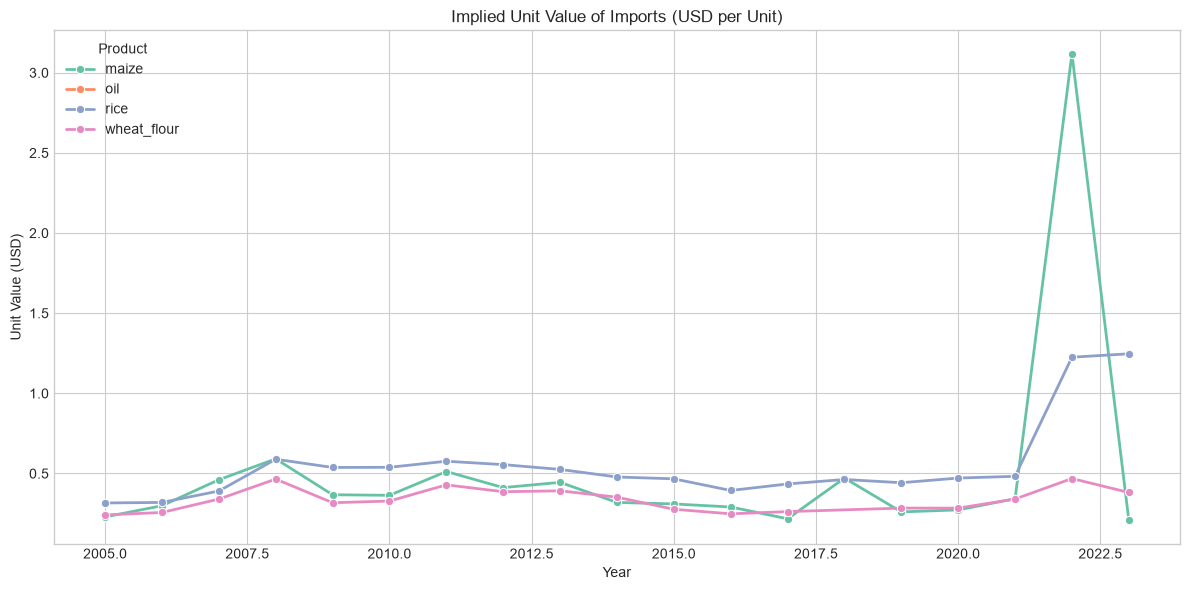

In [5]:
# Calculate unit value (USD per unit)
df_agg['unit_value'] = df_agg['import_value'] / df_agg['import_quantity']

plt.figure(figsize=(12, 6))
sns.lineplot(data=df_agg, x='year', y='unit_value', hue='product_name', marker='o', linewidth=2)
plt.title("Implied Unit Value of Imports (USD per Unit)")
plt.xlabel("Year")
plt.ylabel("Unit Value (USD)")
plt.legend(title="Product")
plt.tight_layout()
plt.show()

## 5. Commodity Composition

Let's look at the total volume imported across all years to see which of the four commodities dominates the trade profile.

C:\Users\visi\AppData\Local\Temp\ipykernel_9584\635497519.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=total_vol, x='product_name', y='import_quantity', palette='viridis')


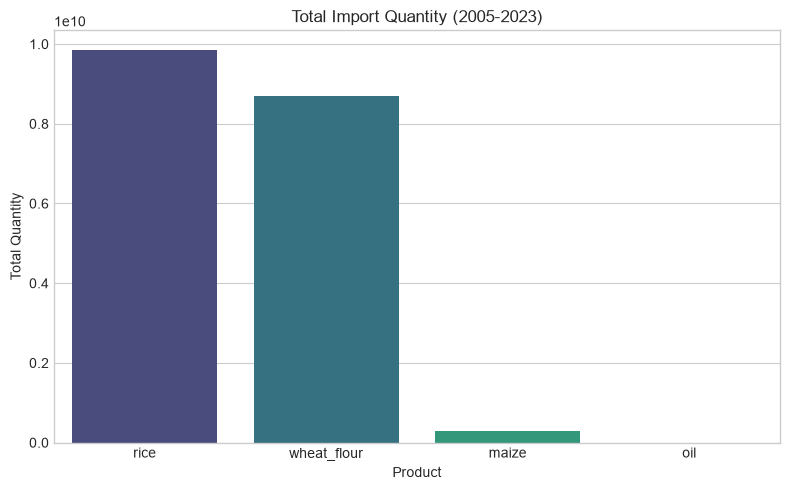

In [6]:
total_vol = df_agg.groupby('product_name')['import_quantity'].sum().sort_values(ascending=False).reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=total_vol, x='product_name', y='import_quantity', palette='viridis')
plt.title("Total Import Quantity (2005-2023)")
plt.xlabel("Product")
plt.ylabel("Total Quantity")
plt.tight_layout()
plt.show()

## 6. Trade Partners

Are these imports coming from one dominant partner, or are they diversified? We look at the total import value by partner country.

C:\Users\visi\AppData\Local\Temp\ipykernel_9584\3968941859.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_partners, x='import_value', y='partner_country', palette='magma')


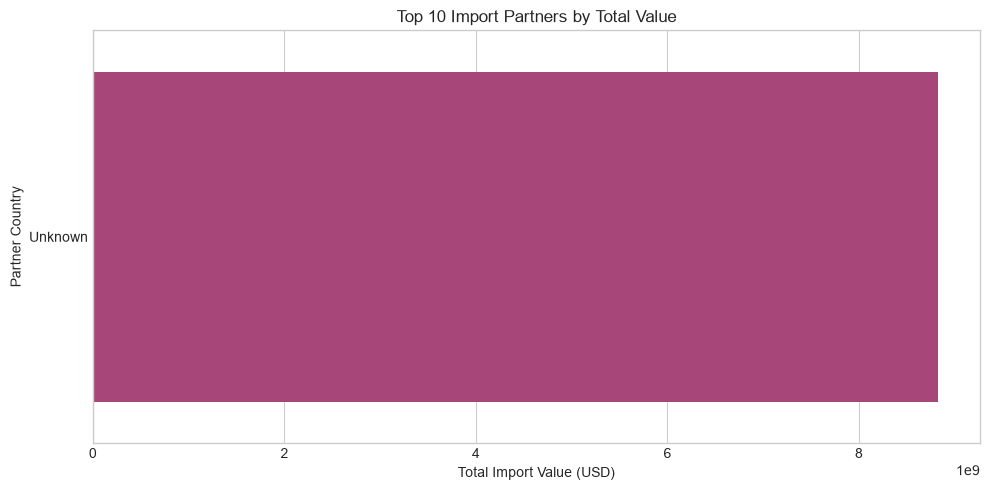

,partner_country,import_value
0,Unknown,8.822361e+09


In [7]:
# Group by partner
partner_agg = df.groupby('partner_country')['import_value'].sum().sort_values(ascending=False).reset_index()

# Take top 10 partners
top_partners = partner_agg.head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_partners, x='import_value', y='partner_country', palette='magma')
plt.title("Top 10 Import Partners by Total Value")
plt.xlabel("Total Import Value (USD)")
plt.ylabel("Partner Country")
plt.tight_layout()
plt.show()

display(top_partners.head())